# 05 · Bản chính: dự báo 4 bước và P10/P50/P90

Mô hình đóng gói ngày 14/10/2026 từ CSV UCI thật. Notebook đọc artifact đã khóa; không train lại, không ghi đè policy. So sánh baseline/Ridge/HGB trên validation tháng 9; calibration tháng 10; test tháng 11–12 là đánh giá hồi cứu đã từng quan sát.

In [1]:
from pathlib import Path
import sys
import json
ROOT = Path.cwd()
if not (ROOT / "src/steel").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/steel").is_dir():
    raise FileNotFoundError("Mở notebook từ repo hoặc notebooks/")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.steel.preprocessing import (load_official_raw, build_supervised_rows,
    split_supervised_rows, BASE_FEATURES, TARGET)
from src.steel.duy_forecasting import forecast_features
raw, audit = load_official_raw(ROOT / "data/steel/raw/Steel_industry_data.csv")
from src.steel.probabilistic import ProbabilisticForecaster, attach_observed_actuals
RUN = ROOT / "reports/steel/release_2026-10-14"
model = ProbabilisticForecaster(RUN, audit["source_sha256"])
metrics = json.loads((RUN / "metrics.json").read_text(encoding="utf-8"))

## 1. So sánh phương pháp

Last value lặp Usage cuối cho 4 bước; Ridge dùng scaler TRAIN; HGB dùng 4 model point. Chọn bằng MAE validation, không chọn bằng test.

In [2]:
display(pd.read_csv(RUN / "point_model_comparison.csv"))
print("Đã chọn:", metrics["selected_point_method"])
display(pd.DataFrame(metrics["splits"]["test"]["point"]["per_step"]))

,model,split,mae_kWh,rmse_kWh,sum_hour_mae_kWh,sum_hour_rmse_kWh
0,last_value,validation,7.375043,16.951942,26.902191,60.118891
1,last_value,test,8.636489,18.542282,31.814023,66.425861
2,ridge,validation,9.220711,14.847859,32.944186,50.952822
3,ridge,test,10.104695,15.940111,36.070672,55.407839
4,hgb,validation,4.766497,10.007463,15.448805,31.528981
5,hgb,test,5.003358,10.032415,16.066122,31.977080


Đã chọn: hgb


,minutes,mae_kWh,rmse_kWh
0,15,3.855797,7.996994
1,30,4.763171,9.583820
2,45,5.368685,10.693304
3,60,6.025777,11.855541


## 2. Phân vị và calibration

P50 là trung vị, không phải trung bình. Sáu HGB quantile riêng cho tổng giờ và max interval; không cộng các phân vị của từng bước. P10–P90 có mức phủ danh nghĩa 80%, không bảo đảm 80% trên chuỗi thời gian. Biên calibration chỉ lấy tháng 10.

,p50_mae_kWh,raw_p10_p90_coverage,calibrated_coverage,calibrated_mean_width_kWh
hour_total,16.095077,0.719241,0.783322,55.261641
max_interval,5.551997,0.714798,0.796651,19.517163


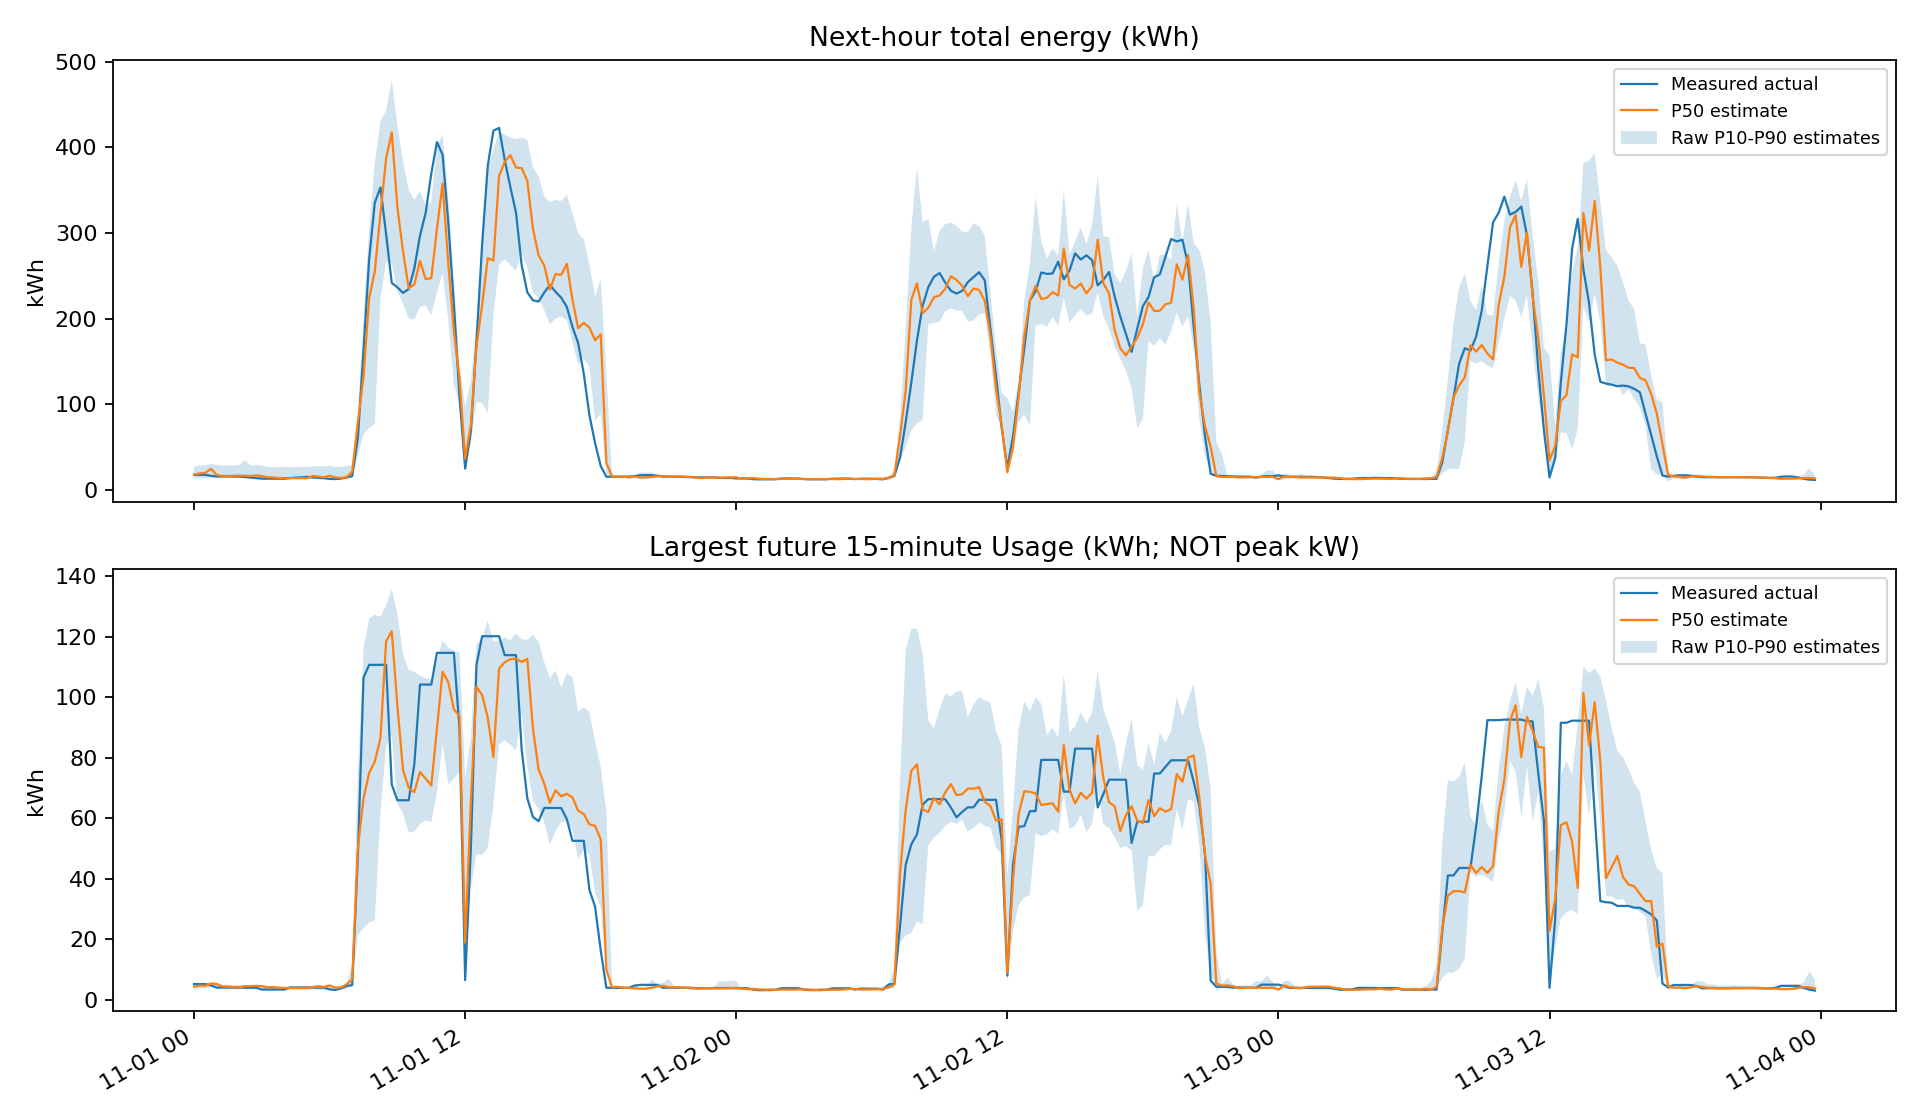

Research alert: {'rows': 5852, 'tp': 155, 'fp': 186, 'fn': 24, 'tn': 5487, 'alert_rows': 341, 'precision': 0.45454545454545453, 'recall': 0.8659217877094972, 'f1': 0.5961538461538461, 'false_positive_rate': 0.03278688524590164, 'false_discovery_rate': 0.5454545454545454, 'roc_auc_ranking': 0.9815700559447034, 'true_origin_episodes': 33, 'alert_origin_episodes': 73, 'detected_true_episodes': 24, 'overlap_episode_precision': 0.3150684931506849, 'overlap_episode_recall': 0.7272727272727273, 'episode_note': 'Many-to-many overlap at forecast origins; not physical load events or 60-minute lead-time proof', 'threshold_kWh': 379.7710000000002, 'definition': 'actual hour total > TRAIN p95; alert = calibrated quantile upper > same threshold', 'contract_power_limit_available': False, 'savings_measured': False, 'lead_time_measured': False}


In [3]:
display(pd.DataFrame(metrics["splits"]["test"]["quantiles"]).T[["p50_mae_kWh", "raw_p10_p90_coverage", "calibrated_coverage", "calibrated_mean_width_kWh"]])
display(Image(filename=str(RUN / "figures/test_quantiles.png")))
print("Research alert:", metrics["splits"]["test"]["research_alert"])

## 3. Dự báo chỉ dùng lịch sử đã có

673 số đo liên tiếp kết thúc tại t tạo 15 feature. Actual 4 bước chưa có tại lúc phát dự báo. Minh họa lấy origin đầu TEST có thật.

In [4]:
issue = pd.Timestamp("2018-11-01 08:00:00")
history = raw.loc[raw.observation_time <= issue, ["observation_time", "Usage_kWh"]].tail(673)
forecast = model.predict(history, issue)
display(pd.DataFrame(forecast["intervals"]))
display(pd.Series(forecast["hour_total"]))
assert all(step["actual_kWh"] is None for step in forecast["intervals"])
assert forecast["research_alert"]["contract_power_limit"] is None

,time,predicted_kWh,actual_kWh
0,2018-11-01T08:15:00,48.671291,None
1,2018-11-01T08:30:00,86.186750,None
2,2018-11-01T08:45:00,88.670837,None
3,2018-11-01T09:00:00,92.089546,None


p10_kWh                  77.117663
p50_kWh                 255.597042
p90_kWh                 382.142486
calibrated_lower_kWh     76.805736
calibrated_upper_kWh    382.454413
raw_width_kWh           305.024824
crossing_reordered           False
actual_kWh                    None
dtype: object

## 4. Actual xuất hiện khi số đo đến

Replay là mô phỏng dòng dữ liệu đã ghi lại, không phải đo từ nhà máy hiện tại. Không điền actual tương lai vào trạng thái tại t.

In [5]:
for k in range(5):
    now = issue + pd.Timedelta(minutes=15*k)
    observed = raw.loc[raw.observation_time.between(issue, now)]
    updated = attach_observed_actuals(forecast, observed, now)
    available = sum(step["actual_kWh"] is not None for step in updated["intervals"])
    print(now, "Số actual đã đến:", available, "Tổng actual:", updated["hour_total"]["actual_kWh"])
    assert available == k
assert forecast["hour_total"]["actual_kWh"] is None

2018-11-01 08:00:00 Số actual đã đến: 0 Tổng actual: None
2018-11-01 08:15:00 Số actual đã đến: 1 Tổng actual: None
2018-11-01 08:30:00 Số actual đã đến: 2 Tổng actual: None
2018-11-01 08:45:00 Số actual đã đến: 3 Tổng actual: None
2018-11-01 09:00:00 Số actual đã đến: 4 Tổng actual: 335.56


## 5. Giá trị và giới hạn

Cảnh báo biên trên vượt p95 TRAIN giúp người điều độ ưu tiên kiểm tra. Ngưỡng nghiên cứu không phải P_limit. Max interval vẫn là kWh, chưa phải peak kW. Không có biểu giá, lịch máy, BESS hay số tiền tiết kiệm thực. Xem notebook 06 cho ca TP/FN của Khánh và README để chạy dashboard.